# LesioScan — 04 Validation Evaluation

**No training, no final test.** Loads the best ShuffleNet V2 fine-tuning checkpoint, computes validation classification metrics, confusion matrices, per-class recall, and prediction examples. Original images stay on Drive.

## 1. Google Drive dan source GitHub

In [1]:
from pathlib import Path
import subprocess, sys
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not in Colab: configure local paths below.')
REPO = Path('/content/lesioscan-ml')
if not REPO.exists():
    subprocess.run(['git','clone','https://github.com/Liex2810/lesioscan-ml.git',str(REPO)],check=True)
else:
    print('Repo found:',REPO)
print('Evaluation module present:',(REPO/'src/lesioscan/evaluation.py').is_file())
assert (REPO/'src/lesioscan/evaluation.py').is_file(), 'Tambahkan modul evaluation.py ke GitHub lalu clone/pull ulang.'

Mounted at /content/drive
Evaluation module present: True


## 2. Konfigurasi lokasi dataset dan checkpoint

In [2]:
ROOT=Path('/content/drive/MyDrive/LesioScan-AI')
DATASET=ROOT/'datasets/PAD-UFES-20'
SPLIT=ROOT/'experiments/splits/split.csv'
TRAIN_OUT=ROOT/'experiments/training/shufflenet_v2_baseline'
EVAL_OUT=TRAIN_OUT/'validation_evaluation'
for path in [DATASET,SPLIT,TRAIN_OUT/'fine_tuning/best_finetuning.pt']:
    print('✅' if path.exists() else '❌',path)
    assert path.exists(), f'Missing: {path}'
EVAL_OUT.mkdir(parents=True,exist_ok=True)
print('Report output:',EVAL_OUT)

✅ /content/drive/MyDrive/LesioScan-AI/datasets/PAD-UFES-20
✅ /content/drive/MyDrive/LesioScan-AI/experiments/splits/split.csv
✅ /content/drive/MyDrive/LesioScan-AI/experiments/training/shufflenet_v2_baseline/fine_tuning/best_finetuning.pt
Report output: /content/drive/MyDrive/LesioScan-AI/experiments/training/shufflenet_v2_baseline/validation_evaluation


## 3. Jalankan validation inference (tidak melakukan training)

`--trust-own-checkpoint` diperlukan hanya untuk konversi pertama checkpoint lama buatanmu yang mengandung NumPy RNG state. Jangan gunakan untuk file pihak lain.

In [4]:
from pathlib import Path
import ast

EVAL_MODULE = REPO / "src/lesioscan/evaluation.py"

source = EVAL_MODULE.read_text(encoding="utf-8")

OLD_LOOP = """        for x,y in tqdm(loader,desc='Validation inference',unit='batch'):
"""

NEW_LOOP = """        total_batches = len(loader)

        print(
            f"[EVAL_BATCH_START] total={total_batches} images={len(val)}",
            flush=True
        )

        for batch_index, (x, y) in enumerate(
            tqdm(loader, desc='Validation inference', unit='batch'),
            start=1
        ):
"""

OLD_END = """            prob.extend(p.tolist())
"""

NEW_END = """            prob.extend(p.tolist())

            completed_images = len(yt)
            batch_percent = batch_index / total_batches * 100

            # Tahap inference menempati 25% hingga 65%
            overall_percent = 25 + 40 * (batch_index / total_batches)

            print(
                f"[EVAL_BATCH] "
                f"{batch_index}/{total_batches} "
                f"images={completed_images}/{len(val)} "
                f"batch_pct={batch_percent:.2f} "
                f"overall_pct={overall_percent:.2f}",
                flush=True
            )
"""

if "[EVAL_BATCH]" not in source:

    if OLD_LOOP not in source:
        raise RuntimeError(
            "Loop validation inference tidak ditemukan. "
            "Periksa versi evaluation.py."
        )

    if OLD_END not in source:
        raise RuntimeError(
            "Bagian akhir loop inference tidak ditemukan."
        )

    source = source.replace(
        OLD_LOOP,
        NEW_LOOP,
        1
    )

    source = source.replace(
        OLD_END,
        NEW_END,
        1
    )

    ast.parse(source)

    EVAL_MODULE.write_text(
        source,
        encoding="utf-8"
    )

print("✅ Detailed evaluation progress berhasil diaktifkan.")

✅ Detailed evaluation progress berhasil diaktifkan.


In [5]:
import subprocess
import sys
import time
import threading
import re

import ipywidgets as widgets

from IPython.display import display

# =====================================================
# LESIOSCAN — DETAILED VALIDATION EVALUATION MONITOR
# =====================================================

overall_bar = widgets.FloatProgress(
    value=0,
    min=0,
    max=100,
    description="Overall:",
    bar_style="info",
    layout=widgets.Layout(width="700px")
)

inference_bar = widgets.FloatProgress(
    value=0,
    min=0,
    max=100,
    description="Inference:",
    bar_style="info",
    layout=widgets.Layout(width="700px")
)

overall_text = widgets.HTML("<b>Overall: 0.00%</b>")
inference_text = widgets.HTML("<b>Inference: 0.00%</b>")

image_text = widgets.HTML("Images: 0 / 339")
batch_text = widgets.HTML("Batches: 0 / 22")

stage_text = widgets.HTML("Stage: Initializing...")
device_text = widgets.HTML("Device: Detecting...")

elapsed_text = widgets.HTML("Elapsed: 00:00:00")

display(
    widgets.HTML(
        "<h3>🔬 LesioScan — Validation Evaluation Monitor</h3>"
    ),
    overall_bar,
    overall_text,
    inference_bar,
    inference_text,
    image_text,
    batch_text,
    stage_text,
    device_text,
    elapsed_text
)

# =====================================================
# COMMAND
# =====================================================

command = [
    sys.executable,
    "-u",
    "scripts/evaluate.py",

    "--split", str(SPLIT),
    "--images", str(DATASET),
    "--training-out", str(TRAIN_OUT),
    "--out", str(EVAL_OUT),

    "--batch-size", "16",
    "--trust-own-checkpoint"
]

# =====================================================
# PROCESS
# =====================================================

started_at = time.monotonic()

process = subprocess.Popen(
    command,
    cwd=REPO,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
    errors="replace"
)

stop_event = threading.Event()

def update_clock():
    while not stop_event.wait(1):
        elapsed = int(time.monotonic() - started_at)

        elapsed_text.value = (
            f"<b>Elapsed:</b> "
            f"{elapsed // 3600:02}:"
            f"{(elapsed % 3600) // 60:02}:"
            f"{elapsed % 60:02}"
        )

timer = threading.Thread(
    target=update_clock,
    daemon=True
)

timer.start()

# =====================================================
# REGEX
# =====================================================

stage_pattern = re.compile(
    r"\[EVAL\s+(\d+)%\]\s*(.*)"
)

batch_pattern = re.compile(
    r"\[EVAL_BATCH\]\s+"
    r"(\d+)/(\d+)\s+"
    r"images=(\d+)/(\d+)\s+"
    r"batch_pct=([\d.]+)\s+"
    r"overall_pct=([\d.]+)"
)

# =====================================================
# STREAM OUTPUT
# =====================================================

logs = []

try:
    for line in process.stdout:

        # tqdm dapat menggunakan carriage return.
        for chunk in re.split(r"[\r\n]+", line):

            chunk = chunk.strip()

            if not chunk:
                continue

            logs.append(chunk)

            if len(logs) > 200:
                logs.pop(0)

            # -----------------------------------------
            # STAGE PROGRESS
            # -----------------------------------------

            stage_match = stage_pattern.search(chunk)

            if stage_match:

                pct = float(stage_match.group(1))
                description = stage_match.group(2)

                overall_bar.value = pct
                overall_text.value = (
                    f"<b>Overall: {pct:.2f}%</b>"
                )

                stage_text.value = (
                    f"<b>Stage:</b> {description}"
                )

                if "Model ready on" in description:
                    device_text.value = (
                        f"<b>Device:</b> "
                        f"{description.split('Model ready on')[-1].strip()}"
                    )

            # -----------------------------------------
            # BATCH PROGRESS
            # -----------------------------------------

            batch_match = batch_pattern.search(chunk)

            if batch_match:

                current_batch = int(batch_match.group(1))
                total_batches = int(batch_match.group(2))

                current_images = int(batch_match.group(3))
                total_images = int(batch_match.group(4))

                batch_pct = float(batch_match.group(5))
                overall_pct = float(batch_match.group(6))

                inference_bar.value = min(
                    100,
                    batch_pct
                )

                overall_bar.value = min(
                    100,
                    overall_pct
                )

                inference_text.value = (
                    f"<b>Inference: {batch_pct:.2f}%</b>"
                )

                overall_text.value = (
                    f"<b>Overall: {overall_pct:.2f}%</b>"
                )

                image_text.value = (
                    f"<b>Images:</b> "
                    f"{current_images} / {total_images}"
                )

                batch_text.value = (
                    f"<b>Batches:</b> "
                    f"{current_batch} / {total_batches}"
                )

                stage_text.value = (
                    "<b>Stage:</b> Running Validation Inference"
                )

    # =================================================
    # COMPLETION
    # =================================================

    return_code = process.wait()

    if return_code != 0:

        overall_bar.bar_style = "danger"
        inference_bar.bar_style = "danger"

        print("\n=== EVALUATION ERROR LOGS ===")
        print("\n".join(logs[-40:]))

        raise RuntimeError(
            f"Evaluation failed: exit code {return_code}"
        )

    overall_bar.value = 100
    inference_bar.value = 100

    overall_bar.bar_style = "success"
    inference_bar.bar_style = "success"

    overall_text.value = "<b>Overall: 100%</b>"
    inference_text.value = "<b>Inference: 100%</b>"

    stage_text.value = "✅ Evaluation Complete"

    print("\n✅ Validation evaluation selesai!")
    print("📁 Results:", EVAL_OUT)

finally:
    stop_event.set()
    timer.join(timeout=2)

    if process.stdout:
        process.stdout.close()

HTML(value='<h3>🔬 LesioScan — Validation Evaluation Monitor</h3>')

FloatProgress(value=0.0, bar_style='info', description='Overall:', layout=Layout(width='700px'))

HTML(value='<b>Overall: 0.00%</b>')

FloatProgress(value=0.0, bar_style='info', description='Inference:', layout=Layout(width='700px'))

HTML(value='<b>Inference: 0.00%</b>')

...

HTML(value='Batches: 0 / 22')

HTML(value='Stage: Initializing...')

HTML(value='Device: Detecting...')

HTML(value='Elapsed: 00:00:00')


✅ Validation evaluation selesai!
📁 Results: /content/drive/MyDrive/LesioScan-AI/experiments/training/shufflenet_v2_baseline/validation_evaluation


## 4. Classification report dan ringkasan

In [6]:
import pandas as pd,json
from IPython.display import display
TABLES=EVAL_OUT/'tables'; FIGURES=EVAL_OUT/'figures'
report=pd.read_csv(TABLES/'classification_report.csv',index_col=0)
display(report.round(4))
summary=json.loads((EVAL_OUT/'validation_summary.json').read_text())
print(json.dumps(summary,indent=2))

,precision,recall,f1-score,support
ACK,0.8416,0.7658,0.8019,111.0000
BCC,0.6917,0.7419,0.7160,124.0000
MEL,0.6000,0.4286,0.5000,7.0000
NEV,0.6154,0.7742,0.6857,31.0000
SCC,0.3077,0.1333,0.1860,30.0000
SEK,0.5833,0.7778,0.6667,36.0000
accuracy,0.6962,0.6962,0.6962,0.6962
macro avg,0.6066,0.6036,0.5927,339.0000
weighted avg,0.6864,0.6962,0.6847,339.0000


{
  "model": "shufflenet_v2_x1_0",
  "checkpoint": "/content/drive/MyDrive/LesioScan-AI/experiments/training/shufflenet_v2_baseline/fine_tuning/best_finetuning_eval.pt",
  "best_epoch": 15,
  "evaluation_split": "val",
  "validation_images": 339,
  "accuracy": 0.696165191740413,
  "balanced_accuracy": 0.6035962229510616,
  "macro_f1": 0.5927112606424476,
  "test_set_evaluated": false,
  "classes": [
    "ACK",
    "BCC",
    "MEL",
    "NEV",
    "SCC",
    "SEK"
  ]
}


## 5. Confusion matrix dan recall

confusion_matrix.png


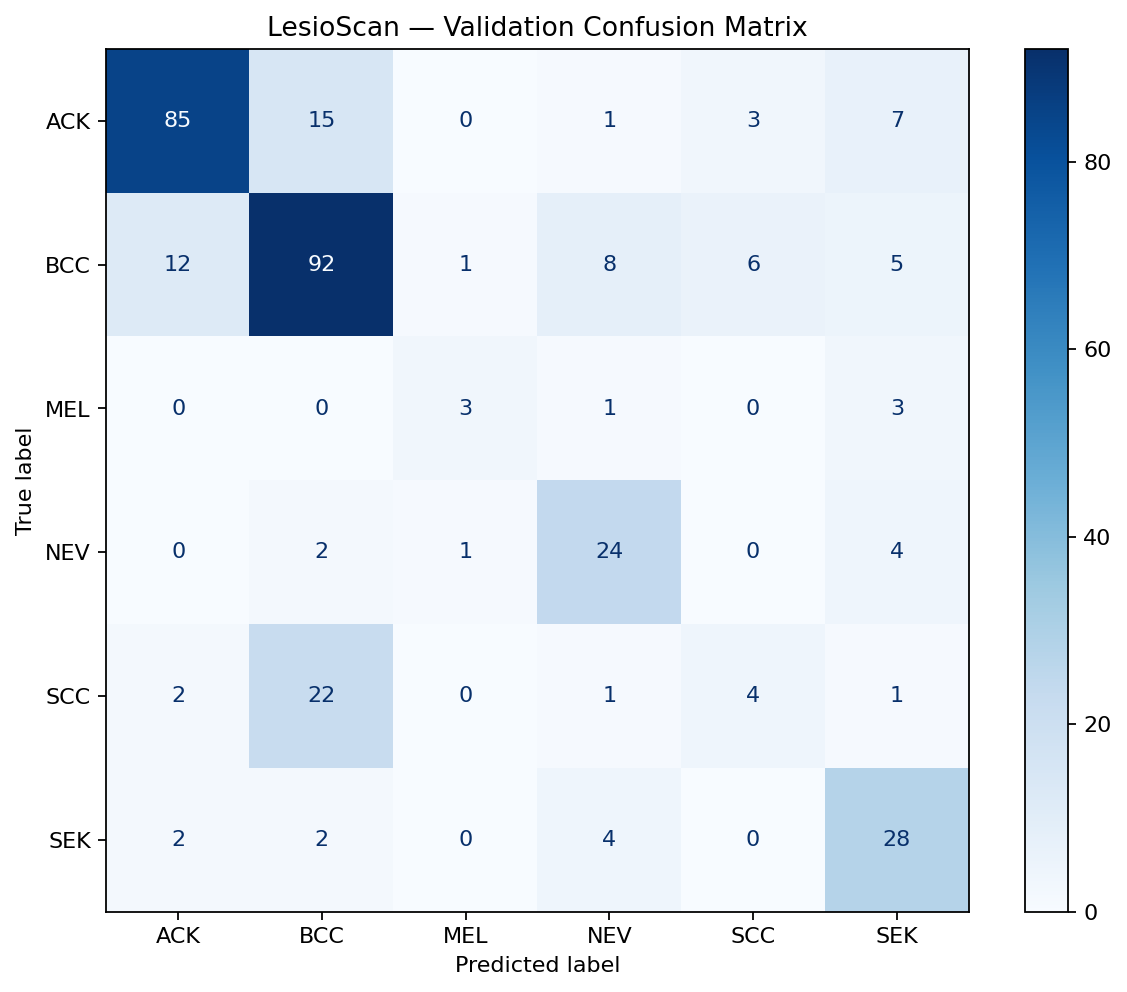

confusion_matrix_normalized.png


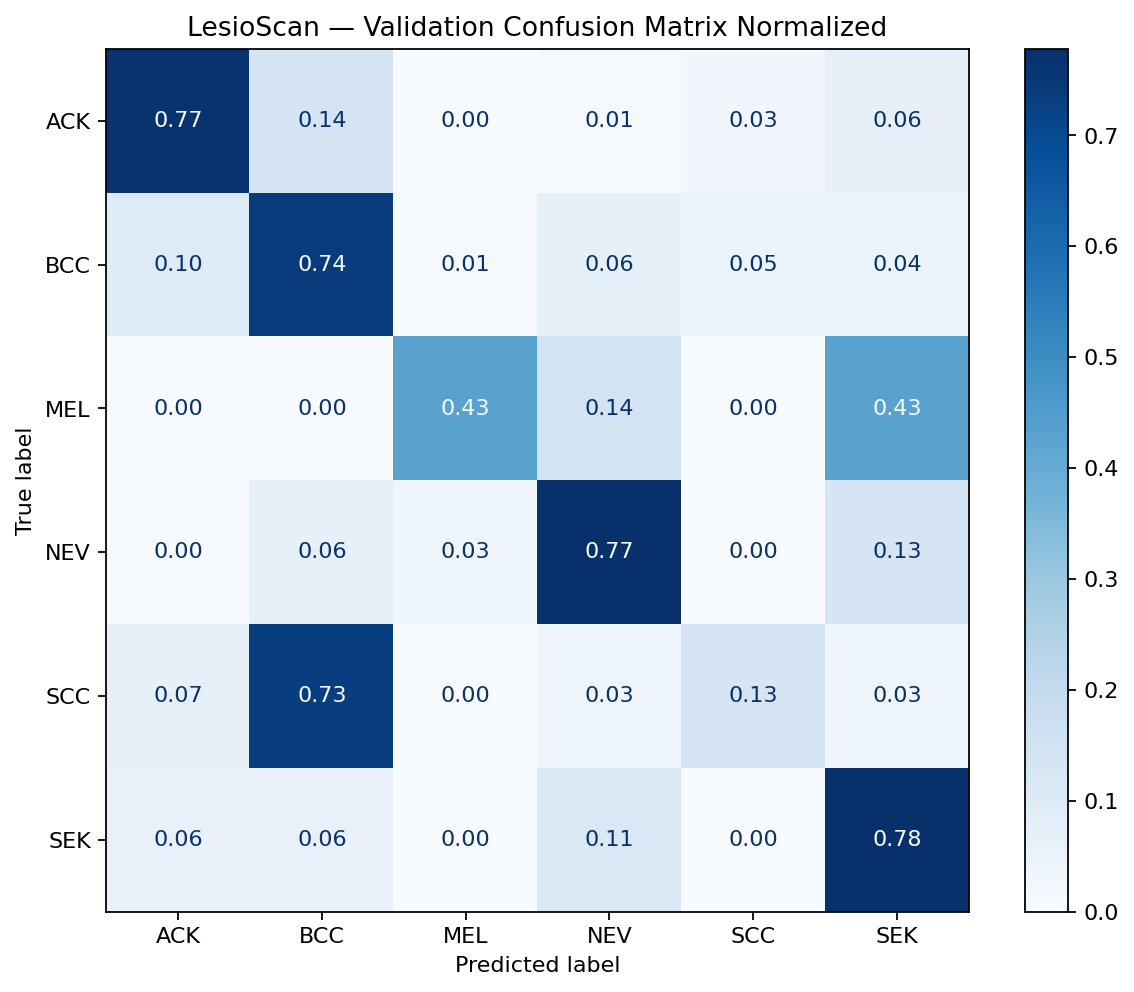

recall_by_class.png


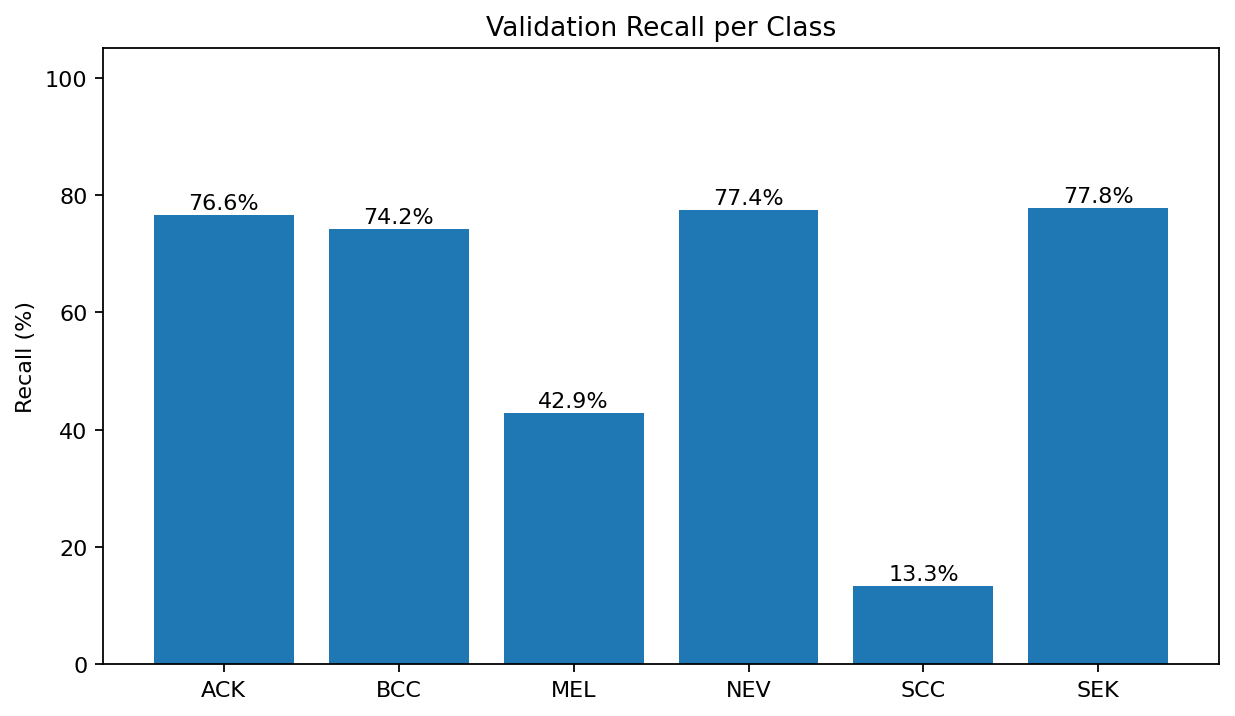

,class,precision,recall,f1_score,support
0,ACK,0.8416,0.7658,0.8019,111
1,BCC,0.6917,0.7419,0.7160,124
2,MEL,0.6000,0.4286,0.5000,7
3,NEV,0.6154,0.7742,0.6857,31
4,SCC,0.3077,0.1333,0.1860,30
5,SEK,0.5833,0.7778,0.6667,36


In [7]:
from IPython.display import Image as DisplayImage,display
for name in ['confusion_matrix.png','confusion_matrix_normalized.png','recall_by_class.png']:
    print(name)
    display(DisplayImage(filename=str(FIGURES/name),width=800))
display(pd.read_csv(TABLES/'per_class_metrics.csv').round(4))

## 6. Contoh prediksi dan kesalahan

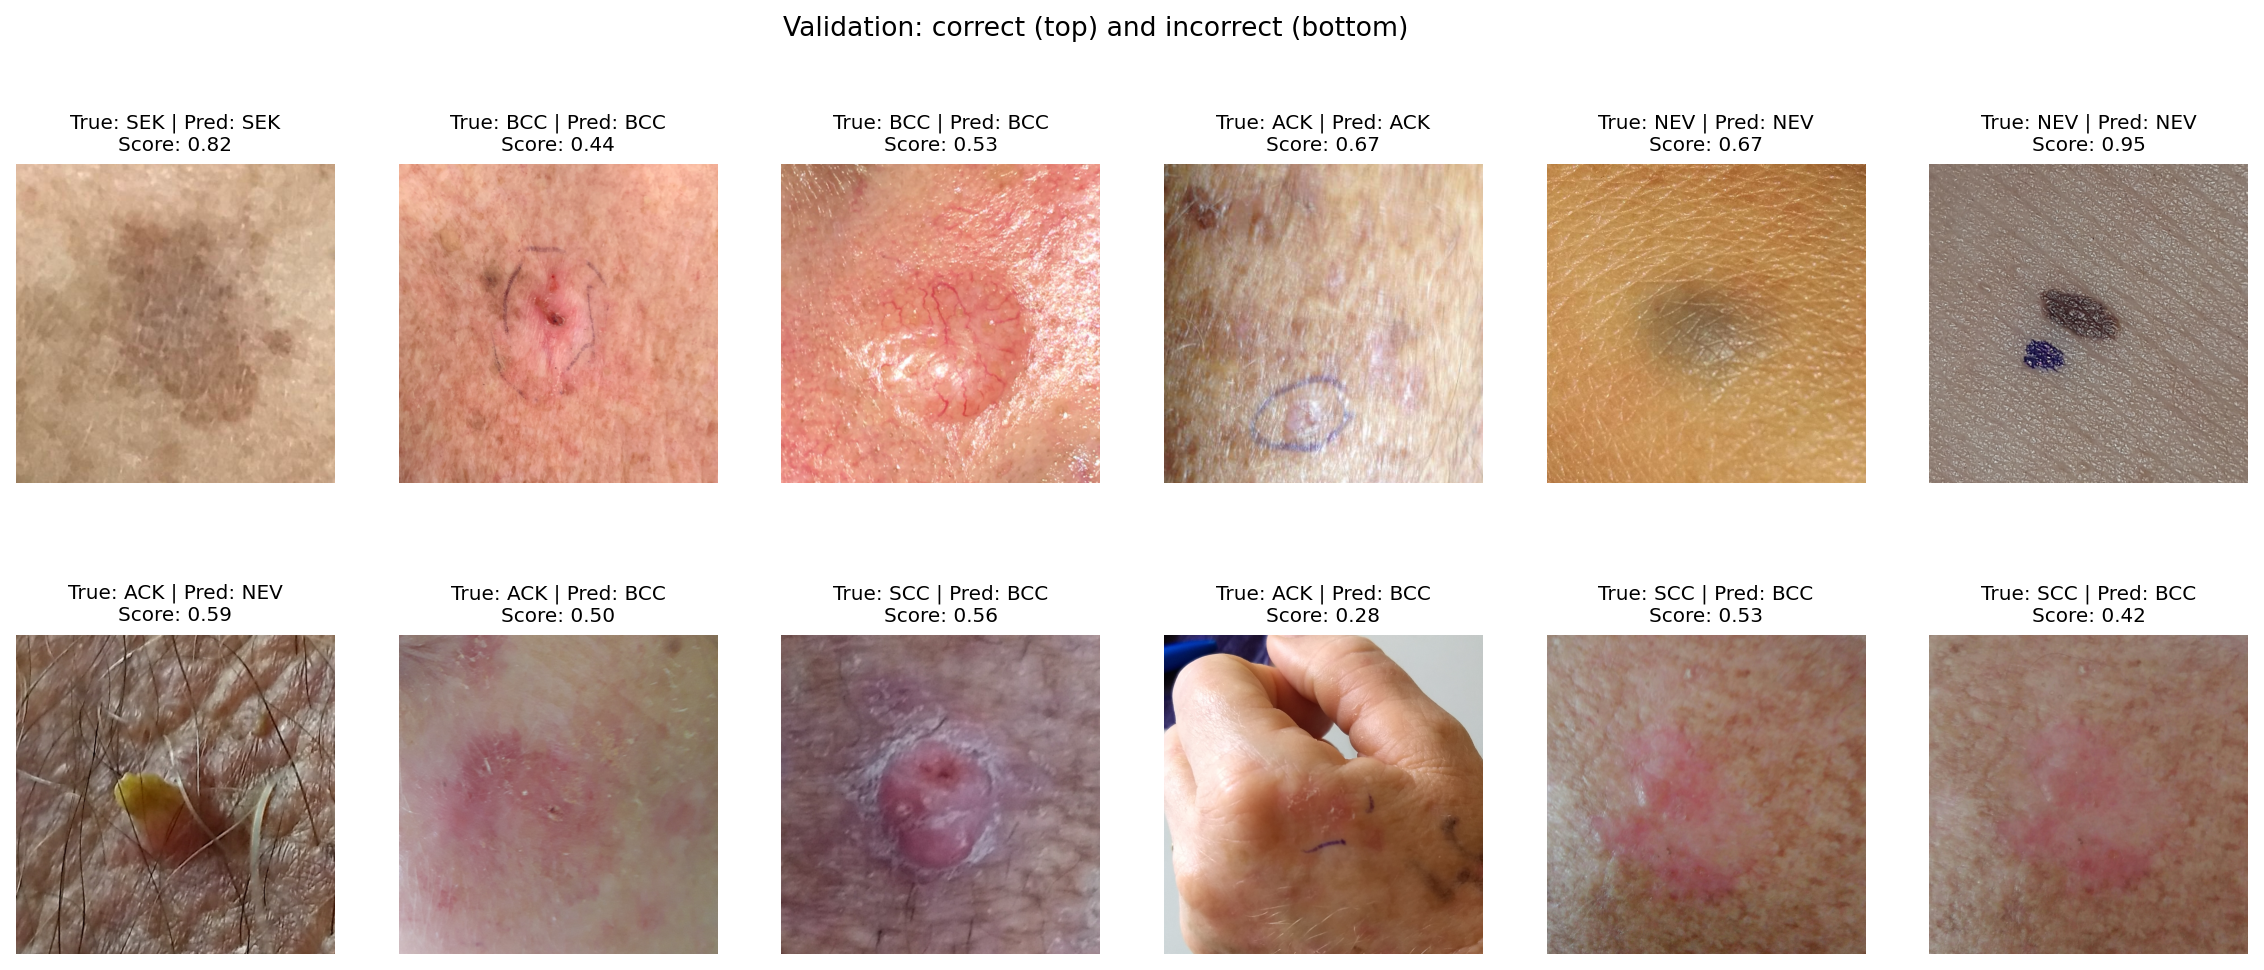

,diagnostic,predicted_class,count
0,SCC,BCC,22
1,ACK,BCC,15
2,BCC,ACK,12
3,BCC,NEV,8
4,ACK,SEK,7
5,BCC,SCC,6
6,BCC,SEK,5
7,NEV,SEK,4
8,SEK,NEV,4
9,MEL,SEK,3


,img_id,diagnostic,true_index,pred_index,predicted_class,confidence,correct,prob_ACK,prob_BCC,prob_MEL,prob_NEV,prob_SCC,prob_SEK
0,PAT_616_1169_3.png,SEK,5,3,NEV,0.969962,False,0.000098,0.000203,0.002857,0.969962,0.000102,0.026779
1,PAT_1520_1777_935.png,NEV,3,2,MEL,0.950024,False,0.000037,0.000570,0.950024,0.036148,0.000624,0.012598
2,PAT_1506_1735_733.png,ACK,0,5,SEK,0.920018,False,0.036429,0.005117,0.009172,0.018062,0.011202,0.920018
3,PAT_1406_1397_669.png,ACK,0,5,SEK,0.902258,False,0.054738,0.001666,0.016288,0.020885,0.004166,0.902258
4,PAT_1249_861_810.png,ACK,0,5,SEK,0.888626,False,0.079202,0.001801,0.006534,0.018529,0.005308,0.888626
5,PAT_890_1693_904.png,MEL,2,3,NEV,0.814511,False,0.000338,0.003139,0.079255,0.814511,0.001547,0.101209
6,PAT_580_1104_684.png,BCC,1,3,NEV,0.804782,False,0.007023,0.103368,0.028645,0.804782,0.031534,0.024648
7,PAT_1563_2425_443.png,SEK,5,3,NEV,0.796404,False,0.000417,0.000563,0.011935,0.796404,0.000470,0.190211
8,PAT_890_1693_454.png,MEL,2,5,SEK,0.703155,False,0.000292,0.000193,0.080334,0.215727,0.000299,0.703155
9,PAT_29_40_561.png,NEV,3,5,SEK,0.654101,False,0.018589,0.008703,0.049709,0.255202,0.013697,0.654101


Predictions CSV: /content/drive/MyDrive/LesioScan-AI/experiments/training/shufflenet_v2_baseline/validation_evaluation/tables/validation_predictions.csv


In [8]:
display(DisplayImage(filename=str(FIGURES/'prediction_samples.png'),width=1100))
display(pd.read_csv(TABLES/'misclassification_pairs.csv').head(15))
display(pd.read_csv(TABLES/'high_confidence_errors.csv').head(10))
print('Predictions CSV:',TABLES/'validation_predictions.csv')

## 7. Audit output

In [9]:
expected=[EVAL_OUT/'validation_summary.json',TABLES/'classification_report.csv',
          TABLES/'validation_predictions.csv',TABLES/'confusion_matrix.csv',
          FIGURES/'confusion_matrix.png',FIGURES/'recall_by_class.png',
          FIGURES/'prediction_samples.png']
for item in expected:
    print('✅' if item.is_file() else '❌',item)
assert all(x.is_file() for x in expected)
assert summary['test_set_evaluated'] is False
print('✅ Validation evaluation selesai; final test tetap tidak digunakan.')

✅ /content/drive/MyDrive/LesioScan-AI/experiments/training/shufflenet_v2_baseline/validation_evaluation/validation_summary.json
✅ /content/drive/MyDrive/LesioScan-AI/experiments/training/shufflenet_v2_baseline/validation_evaluation/tables/classification_report.csv
✅ /content/drive/MyDrive/LesioScan-AI/experiments/training/shufflenet_v2_baseline/validation_evaluation/tables/validation_predictions.csv
✅ /content/drive/MyDrive/LesioScan-AI/experiments/training/shufflenet_v2_baseline/validation_evaluation/tables/confusion_matrix.csv
✅ /content/drive/MyDrive/LesioScan-AI/experiments/training/shufflenet_v2_baseline/validation_evaluation/figures/confusion_matrix.png
✅ /content/drive/MyDrive/LesioScan-AI/experiments/training/shufflenet_v2_baseline/validation_evaluation/figures/recall_by_class.png
✅ /content/drive/MyDrive/LesioScan-AI/experiments/training/shufflenet_v2_baseline/validation_evaluation/figures/prediction_samples.png
✅ Validation evaluation selesai; final test tetap tidak digunakan

In [10]:
import pandas as pd
from IPython.display import display

cm_path = TABLES / "confusion_matrix.csv"

cm = pd.read_csv(cm_path, index_col=0)

print("LESIOSCAN — CONFUSION MATRIX (JUMLAH GAMBAR)")
display(cm)

print("\nJumlah gambar validation per kelas:")
display(cm.sum(axis=1).to_frame("Total Images"))

print("\nJumlah prediksi benar per kelas:")
display(
    pd.DataFrame({
        "Correct": [
            cm.loc[c, c] for c in cm.index
        ],
        "Total": cm.sum(axis=1),
        "Recall (%)": [
            100 * cm.loc[c, c] / cm.loc[c].sum()
            if cm.loc[c].sum() else 0
            for c in cm.index
        ]
    }).round(2)
)

LESIOSCAN — CONFUSION MATRIX (JUMLAH GAMBAR)


,ACK,BCC,MEL,NEV,SCC,SEK
ACK,85,15,0,1,3,7
BCC,12,92,1,8,6,5
MEL,0,0,3,1,0,3
NEV,0,2,1,24,0,4
SCC,2,22,0,1,4,1
SEK,2,2,0,4,0,28



Jumlah gambar validation per kelas:


,Total Images
ACK,111
BCC,124
MEL,7
NEV,31
SCC,30
SEK,36



Jumlah prediksi benar per kelas:


,Correct,Total,Recall (%)
ACK,85,111,76.58
BCC,92,124,74.19
MEL,3,7,42.86
NEV,24,31,77.42
SCC,4,30,13.33
SEK,28,36,77.78
